# 01 - Screening and false-discovery control

Correlation is not cointegration; residual-based tests need MacKinnon critical values; BH controls the expected FALSE-DISCOVERY PROPORTION within one formation-date family, under independence/PRDS - not across repeated screens.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("SYNTHETIC results demonstrate software behaviour; they are not market evidence.")

SYNTHETIC results demonstrate software behaviour; they are not market evidence.


In [2]:
from pairs import data as D
from pairs.screening import engle_granger, johansen, benjamini_hochberg, benjamini_yekutieli
A, _ = D.cointegrated_pair(500, seed=1)
C, _ = D.correlated_random_walks(500, rho=0.9, seed=1)
for name, df in [('cointegrated', A), ('correlated RWs', C)]:
    eg = engle_granger(df['y'], df['x'])
    print(f"{name:14s} return corr={df['y'].diff().corr(df['x'].diff()):.2f}  EG stat={eg.stat:.2f}  5% crit={eg.crit_5:.2f}  p={eg.pvalue:.3g}  Johansen rank={johansen(df['y'], df['x'])['johansen_rank']}")

cointegrated   return corr=0.69  EG stat=-3.94  5% crit=-3.35  p=0.00876  Johansen rank=1
correlated RWs return corr=0.89  EG stat=-2.70  5% crit=-3.35  p=0.199  Johansen rank=0


In [3]:
p = [0.01, 0.04, 0.03, 0.20]
print('BH', benjamini_hochberg(p, 0.05))
print('BY', benjamini_yekutieli(p, 0.05))

BH (array([ True, False, False, False]), array([0.04      , 0.05333333, 0.05333333, 0.2       ]))
BY (array([False, False, False, False]), array([0.08333333, 0.11111111, 0.11111111, 0.41666667]))


In [4]:
display(pd.read_csv(TAB / 'syn_00_calibration.csv'))

,experiment,null_or_truth,replications,rejections,rate,wilson95_low,wilson95_high,share_rank2,mean,bias,sd,share_within_0.05,median,share_within_15pct,power
0,"EG 5% test, independent RWs, n=252",H0 true (no cointegration),300,16.0,0.053333,0.033092,0.084870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"EG 5% test, independent RWs, n=1000",H0 true (no cointegration),300,14.0,0.046667,0.027999,0.076798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"EG 5% test, correlated RWs rho=0.8, n=252",H0 true,300,19.0,0.063333,0.040917,0.096792,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"EG 5% power, cointegrated hl=5, n=252",H1 true,300,287.0,0.956667,0.927282,0.974504,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"EG 5% power, cointegrated hl=10, n=252",H1 true,300,166.0,0.553333,0.496754,0.608564,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,"EG 5% power, cointegrated hl=30, n=252",H1 true,300,29.0,0.096667,0.068150,0.135383,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,"Johansen trace 5%, det_order=0, k=1: rank>=1, ...",H0 true (rank 0),300,26.0,0.086667,0.059828,0.123957,0.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,"beta recovery (true 1.3), n=2000",beta=1.3,300,NaN,NaN,NaN,NaN,NaN,1.301403,0.001403,0.031209,0.893333,NaN,NaN,NaN
8,"OU half-life recovery (true 10), n=2000, true ...",half-life=10,300,NaN,NaN,NaN,NaN,NaN,9.898490,-0.101510,1.236324,NaN,9.911375,0.78,NaN
9,"Variance ratio q=5 robust z, RW t(5) increment...",H0 true,300,17.0,0.056667,0.035677,0.088867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


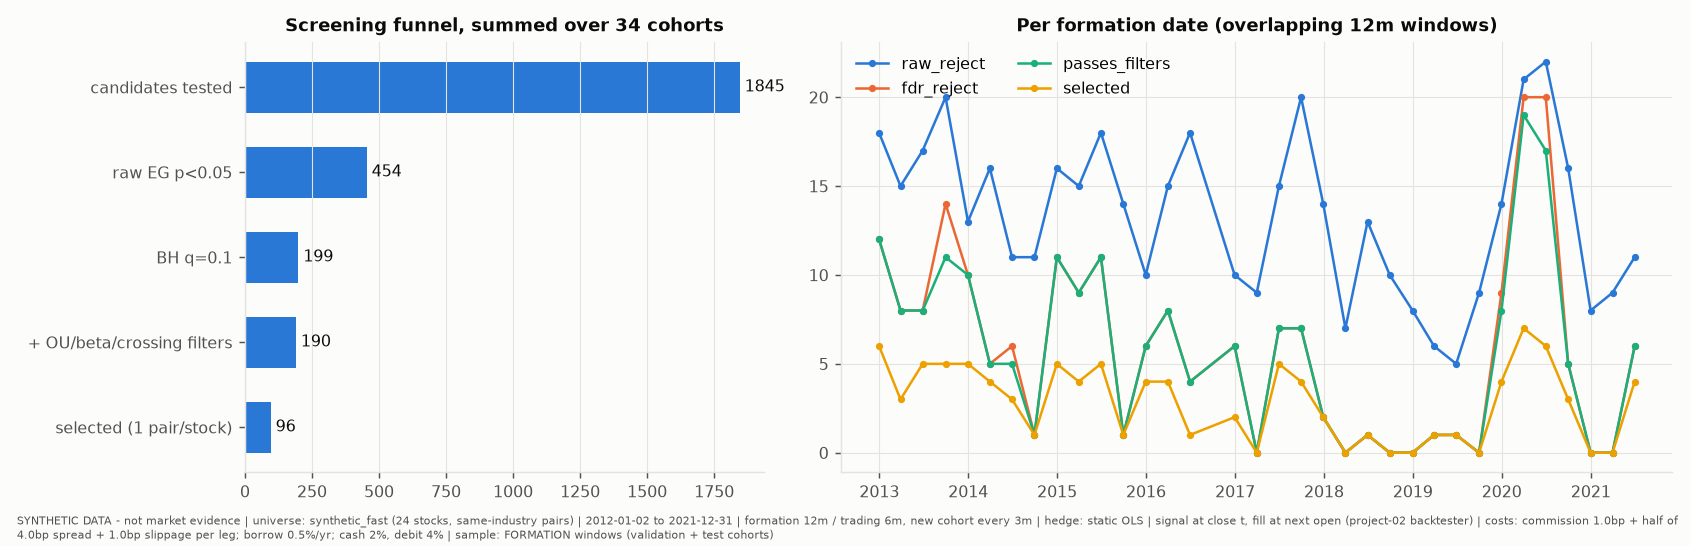

,m,m_true,raw_reject_n,raw_reject_false,raw_reject_fdp,raw_reject_power,fdr_reject_n,fdr_reject_false,fdr_reject_fdp,fdr_reject_power,selected_n,selected_false,selected_fdp,selected_power,by_reject_n,by_reject_false,by_reject_fdp,by_reject_power
mean,54.264706,15.088235,13.352941,6.529412,0.498776,0.441176,5.852941,2.441176,0.285083,0.220588,2.823529,1.0,0.259944,0.116176,0.911765,0.264706,0.097689,0.037582


In [5]:
display(Image(FIG / 'syn_02_screening_funnel.png'))
display(pd.read_csv(TAB / 'syn_02b_screening_vs_truth.csv').describe().T[['mean']].T)

In [6]:
cand = pd.read_csv(TAB / 'syn_03_candidates_first_test_cohort.csv')
display(cand.head(12))

,pair,y,x,sector,eg_stat,eg_pvalue_yx,eg_pvalue_xy,p_pair,p_adj,raw_reject,fdr_reject,beta,ou_half_life,zero_crossings,hurst,vr5,vr5_p_het,johansen_rank,beta_johansen,return_corr,filter_reasons,selected
0,BA02-BA04,BA02,BA04,Banks,-4.525801,0.001110,0.000019,0.001110,0.032135,True,True,1.551909,6.066229,41,0.256588,1.082760,0.535601,1,2.057305,0.653734,NaN,True
1,MI02-MI06,MI02,MI06,Miners,-4.512375,0.001169,0.096939,0.001169,0.032135,True,True,0.279998,5.989360,51,0.347512,0.988225,0.927964,1,0.282006,0.391316,NaN,True
2,BA01-BA04,BA01,BA04,Banks,-4.321706,0.002368,0.000174,0.002368,0.043412,True,True,1.623452,5.473534,33,0.277908,1.037922,0.773256,1,2.158747,0.600069,NaN,False
3,BA01-BA02,BA01,BA02,Banks,-4.168397,0.004071,0.006662,0.004071,0.055977,True,True,0.997268,5.285572,45,0.318681,0.876855,0.346591,1,1.043712,0.783750,NaN,False
4,BA03-BA04,BA03,BA04,Banks,-3.956806,0.008267,0.000744,0.008267,0.089758,True,True,1.489461,5.762528,49,0.215860,1.002980,0.982526,1,1.991756,0.609007,NaN,False
5,BA04-BA05,BA04,BA05,Banks,-3.904073,0.009792,0.149840,0.009792,0.089758,True,True,0.436966,7.292802,31,0.277232,1.106105,0.434797,1,0.430549,0.582835,NaN,False
6,EN01-EN04,EN01,EN04,Energy,-3.770691,0.014825,0.000655,0.014825,0.116481,True,False,1.119507,6.290260,32,0.301872,0.890819,0.413742,1,1.465028,0.620963,not FDR-significant,False
7,BA02-BA03,BA02,BA03,Banks,-3.712056,0.017682,0.012665,0.017682,0.121561,True,False,0.989506,6.914818,31,0.401981,0.909155,0.505832,1,1.065821,0.859837,not FDR-significant,False
8,MI02-MI04,MI02,MI04,Miners,-3.540563,0.028965,0.045295,0.028965,0.177008,True,False,0.775517,7.069978,28,0.275617,0.798389,0.136492,2,0.878004,0.729860,not FDR-significant,False
9,MI04-MI06,MI04,MI06,Miners,-3.492433,0.033072,0.494632,0.033072,0.181896,True,False,0.264916,12.230372,28,0.432101,1.234966,0.072733,0,0.226729,0.424947,not FDR-significant,False


In [7]:
mk = TAB / 'mkt_02_screening_funnel_by_cohort.csv'
if mk.exists():
    f = pd.read_csv(mk); print('MARKET: cohorts', len(f), 'with no selection', int((f.selected == 0).sum()))
    display(f[['candidates','raw_reject','fdr_reject','selected']].sum())

MARKET: cohorts 42 with no selection 24


candidates    2688
raw_reject     232
fdr_reject      39
selected        27
dtype: int64